In [1]:
from pysr import PySRRegressor

import torch
import torch.nn as nn
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import matplotlib.animation as animation

from scipy.special import ive
from scipy import integrate
from scipy.optimize import brentq
from scipy.interpolate import interp1d
from IPython.display import HTML, display

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cuda':
    torch.cuda.manual_seed_all(42)
    torch.backends.cudnn.benchmark = True
    print(f"Using device: {device} ({torch.cuda.get_device_name(0)})")
else:
    print(f"Using device: {device}")

# Parâmetros de entrada (Buckley-Leverett)
mu_g = 6.15e-5   # Viscosidade do gás supercrítico [Pa.s]
mu_w = 7.16e-4   # Viscosidade da salmoura [Pa.s]
phi = 0.156      # Porosidade [-]
k = 5.23e-14     # Permeabilidade absoluta [m²]
L = 0.609        # Comprimento do testemunho [m]
D = 0.0715       # Diâmetro [m]
n_g = 1.60       # Expoente de Corey – gás [-]
n_w = 4.31       # Expoente de Corey – água [-]
S_wc = 0.237     # Saturação de água conata [-]
c_krg = 1.00     # Coeficiente do gás [-]
c_krw = 1.00     # Coeficiente da água [-]
Q_t = 6.67e-8    # Vazão volumétrica total [m³/s]
f_w_in = 0.0     # Fração volumétrica de água injetada na entrada

# Parâmetros calculados
M = (mu_w / mu_g) * (c_krg / c_krw)
A_sec = 0.25 * np.pi * D**2
u_t = (4.0 * Q_t) / (np.pi * D**2)

def fw_np(S):
    S_c = np.clip(S, 0.0, 1.0)
    return (S_c ** n_w) / ((S_c ** n_w) + M * ((1.0 - S_c) ** n_g) + 1e-15)

def dfw_dS_np(S):
    S_c = np.clip(S, 1e-7, 1.0 - 1e-7)
    num = M * (S_c ** (n_w - 1.0)) * ((1.0 - S_c) ** (n_g - 1.0)) * (n_w * (1.0 - S_c) + n_g * S_c)
    den = ((S_c ** n_w) + M * ((1.0 - S_c) ** n_g)) ** 2
    return num / den

S_E = 0.0 if f_w_in <= 0.0 else (1.0 if f_w_in >= 1.0 else brentq(lambda s: fw_np(s) - f_w_in, 0.0, 1.0))
S_star = brentq(lambda s: dfw_dS_np(s) * (1.0 - s) - (1.0 - fw_np(s)), max(S_E + 1e-5, 1e-5), 1.0 - 1e-5)
sigma = (1.0 - fw_np(S_star)) / (1.0 - S_star)
T_bt = (L * phi * (1.0 - S_wc)) / (u_t * sigma)

s_raref = np.linspace(S_E, S_star, 5000)
inv_dfw = interp1d(dfw_dS_np(s_raref), s_raref, bounds_error=False, fill_value=(S_E, S_star))

print(f"M = {M:.4f} | u_t = {u_t:.4e} m/s | S_E = {S_E:.4f} | S* = {S_star:.4f} | sigma = {sigma:.4f} | T_bt = {T_bt:.2f} s")

Using device: cuda (NVIDIA GeForce RTX 3060)
M = 11.6423 | u_t = 1.6612e-05 m/s | S_E = 0.0000 | S* = 0.8327 | sigma = 3.5540 | T_bt = 1227.78 s


In [2]:
_ACTIVATIONS = {
    'tanh': torch.tanh,
    'silu': torch.nn.functional.silu,
    'gelu': torch.nn.functional.gelu,
}

class PINN(nn.Module):
    def __init__(self, layers, activation='tanh', sigma_shock=None, steep=50.0):
        super().__init__()
        if activation not in _ACTIVATIONS:
            raise ValueError(f"Ativação não suportada: {activation}. Use {list(_ACTIVATIONS)}")
        self.act = _ACTIVATIONS[activation]
        self.sigma_shock = sigma_shock
        self.steep = steep
        in_dim = layers[0] + (2 if sigma_shock is not None else 0)
        full_layers = [in_dim] + list(layers[1:])
        self.layers = nn.ModuleList([
            nn.Linear(full_layers[i], full_layers[i + 1]) for i in range(len(full_layers) - 1)
        ])
        self.a = nn.ParameterList([
            nn.Parameter(torch.ones(1, full_layers[i + 1])) for i in range(len(full_layers) - 2)
        ])
        for layer in self.layers:
            nn.init.xavier_normal_(layer.weight)
            nn.init.zeros_(layer.bias)

    def forward(self, x, t):
        if self.sigma_shock is not None:
            d_shock = x - self.sigma_shock * t
            behind_shock = torch.sigmoid(self.steep * (-d_shock))
            inputs = torch.cat([x, t, d_shock, behind_shock], dim=1)
        else:
            inputs = torch.cat([x, t], dim=1)
        for i, layer in enumerate(self.layers[:-1]):
            inputs = self.act(self.a[i] * layer(inputs))
        return self.layers[-1](inputs)

In [3]:
def _grads(model, x, t):
    x = x.clone().detach().requires_grad_(True)
    t = t.clone().detach().requires_grad_(True)
    u = model(x, t)
    ones = torch.ones_like(u)
    u_t = torch.autograd.grad(u, t, ones, create_graph=True, retain_graph=True)[0]
    u_x = torch.autograd.grad(u, x, ones, create_graph=True, retain_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, x, torch.ones_like(u_x), create_graph=True, retain_graph=True)[0]
    return u, u_t, u_x, u_xx

def compute_heat_residual(model, x, t, param=0.01):
    _, u_t, _, u_xx = _grads(model, x, t)
    return u_t - param * u_xx

def compute_burgers_residual(model, x, t, param=0.01):
    u, u_t, u_x, u_xx = _grads(model, x, t)
    return u_t + u * u_x - param * u_xx

def compute_buckley_leverett_residual(model, x, t, param=0.005):
    x = x.clone().detach().requires_grad_(True)
    t = t.clone().detach().requires_grad_(True)
    u = model(x, t)
    u_c = torch.clamp(u, 1e-5, 1-1e-5)
    f_w = (u_c**n_w) / ((u_c**n_w) + M * ((1-u_c)**n_g))
    ones = torch.ones_like(u)
    u_t = torch.autograd.grad(u, t, ones, create_graph=True, retain_graph=True)[0]
    u_x = torch.autograd.grad(u, x, ones, create_graph=True, retain_graph=True)[0]
    u_xx= torch.autograd.grad(u_x, x, torch.ones_like(u_x), create_graph=True, retain_graph=True)[0]
    fw_x= torch.autograd.grad(f_w, x, torch.ones_like(f_w), create_graph=True, retain_graph=True)[0]
    res = u_t + fw_x - param * u_xx
    if getattr(model, 'sigma_shock', None) is not None:
        mask = 1.0 - torch.exp(-((x - model.sigma_shock * t) / 0.03) ** 2)
        res = res * mask
    return res

ic_sin_pi = lambda x: torch.sin(np.pi * x)
ic_burgers = lambda x: -torch.sin(np.pi * x)
ic_buckley_leverett = lambda x: torch.ones_like(x)
bc_zero = lambda t: torch.zeros_like(t)
bc_buckley_leverett = lambda t: torch.full_like(t, S_E)

In [4]:
def compute_rh_loss(model, t_shock, sigma_val, s_star=S_star, n_w=n_w, M=M, n_g=n_g):
    with torch.no_grad():
        x_s = (sigma_val * t_shock).clamp(0.0, 1.0)
    eps = 0.015
    x_behind = (x_s - eps).clamp(0.0, 1.0)
    x_ahead  = (x_s + eps).clamp(0.0, 1.0)

    S_L = model(x_behind, t_shock)
    S_R = model(x_ahead,  t_shock)

    def fw(S):
        S_c = torch.clamp(S, 1e-5, 1 - 1e-5)
        return (S_c ** n_w) / ((S_c ** n_w) + M * ((1 - S_c) ** n_g) + 1e-12)

    f_L, f_R = fw(S_L), fw(S_R)
    residual_rh = (f_L - f_R) - sigma_val * (S_L - S_R)
    residual_jump = (S_L - s_star) ** 2 + (S_R - 1.0) ** 2
    return torch.mean(residual_rh ** 2 + residual_jump)

In [5]:
def train_pinn(model, residual_fn, ic_fn, bc_fn, param=0.005,
               n_epochs=5000, lr=0.001, n_collocation=10000,
               n_initial=250, n_boundary=250,
               w_pde=1.0, w_ic=20.0, w_bc=20.0, w_rh=5.0,
               x_range=(0.0, 1.0), bc_left_only=False,
               use_adaptive_collocation=False,
               sigma_shock=None):

    x_lo, x_hi = x_range
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=n_epochs, eta_min=1e-5
    )
    losses = []

    for epoch in range(n_epochs):
        optimizer.zero_grad()

        if sigma_shock is not None:
            progress = min(1.0, epoch / (0.7 * n_epochs))
            current_param = param * (10.0 * (1.0 - progress) + 1.0 * progress)
        else:
            current_param = param

        if use_adaptive_collocation and sigma_shock is not None:
            half = n_collocation // 2
            t_rand = torch.rand(half, 1, device=device)
            t_bt_max = min(1.0, (x_hi - x_lo) / sigma_shock)
            t_near = t_bt_max * torch.rand(n_collocation - half, 1, device=device)
            t_pde_all = torch.cat([t_rand, t_near], dim=0).requires_grad_(True)

            x_rand = x_lo + (x_hi - x_lo) * torch.rand(half, 1, device=device)
            x_center = (x_lo + sigma_shock * t_near).clamp(x_lo, x_hi)
            x_near = (x_center + 0.04 * torch.randn_like(x_center)).clamp(x_lo, x_hi)
            x_pde = torch.cat([x_rand, x_near], dim=0).requires_grad_(True)
        else:
            t_pde_all = torch.rand(n_collocation, 1, device=device, requires_grad=True)
            x_pde = (x_lo + (x_hi - x_lo) * torch.rand(
                n_collocation, 1, device=device)).requires_grad_(True)

        x_ic = x_lo + (x_hi - x_lo) * torch.rand(n_initial, 1, device=device)
        t_ic = torch.zeros(n_initial, 1, device=device)
        t_bc = torch.rand(n_boundary, 1, device=device)
        x_bc_left  = torch.full((n_boundary, 1), x_lo, dtype=torch.float32, device=device)
        x_bc_right = torch.full((n_boundary, 1), x_hi, dtype=torch.float32, device=device)

        loss_pde = torch.mean(
            residual_fn(model, x_pde, t_pde_all, current_param) ** 2
        )
        loss_ic  = torch.mean((model(x_ic, t_ic) - ic_fn(x_ic)) ** 2)
        u_bc     = bc_fn(t_bc)
        if bc_left_only:
            loss_bc = torch.mean((model(x_bc_left, t_bc) - u_bc) ** 2)
        else:
            loss_bc = (torch.mean((model(x_bc_left,  t_bc) - u_bc) ** 2) +
                       torch.mean((model(x_bc_right, t_bc) - u_bc) ** 2))

        loss_rh = torch.tensor(0.0, device=device)
        if w_rh > 0.0 and sigma_shock is not None:
            t_bt_max = min(1.0, (x_hi - x_lo) / sigma_shock)
            t_shock_pts = t_bt_max * torch.rand(200, 1, device=device)
            loss_rh     = compute_rh_loss(model, t_shock_pts, sigma_shock)

        loss = (w_pde * loss_pde + w_ic * loss_ic +
                w_bc * loss_bc   + w_rh * loss_rh)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        losses.append(loss.item())

        if (epoch + 1) % 500 == 0:
            print(f"Epoch [{epoch+1}/{n_epochs}]  "
                  f"loss={loss.item():.6f}  "
                  f"pde={loss_pde.item():.6f}  "
                  f"ic={loss_ic.item():.6f}  "
                  f"bc={loss_bc.item():.6f}  "
                  f"rh={loss_rh.item():.6f}")

    print("\n── Refinamento L-BFGS (200 steps) ──")
    optimizer_lbfgs = torch.optim.LBFGS(
        model.parameters(), lr=0.05,
        max_iter=200, history_size=50,
        line_search_fn="strong_wolfe"
    )

    x_pde_lbfgs = (x_lo + (x_hi - x_lo) * torch.rand(
        5000, 1, device=device)).requires_grad_(True)
    t_pde_lbfgs = torch.rand(5000, 1, device=device, requires_grad=True)
    x_ic_l = x_lo + (x_hi - x_lo) * torch.rand(n_initial, 1, device=device)
    t_ic_l = torch.zeros(n_initial, 1, device=device)
    t_bc_l = torch.rand(n_boundary, 1, device=device)
    x_bc_l = torch.full((n_boundary, 1), x_lo, dtype=torch.float32, device=device)
    x_bc_r = torch.full((n_boundary, 1), x_hi, dtype=torch.float32, device=device)
    t_s_lbfgs = None
    if w_rh > 0.0 and sigma_shock is not None:
        t_bt_max = min(1.0, (x_hi - x_lo) / sigma_shock)
        t_s_lbfgs = t_bt_max * torch.rand(200, 1, device=device)

    def closure():
        optimizer_lbfgs.zero_grad()
        lp = torch.mean(residual_fn(model, x_pde_lbfgs, t_pde_lbfgs, param) ** 2)
        li = torch.mean((model(x_ic_l, t_ic_l) - ic_fn(x_ic_l)) ** 2)
        u_bc_l = bc_fn(t_bc_l)
        if bc_left_only:
            lb = torch.mean((model(x_bc_l, t_bc_l) - u_bc_l) ** 2)
        else:
            lb = (torch.mean((model(x_bc_l, t_bc_l) - u_bc_l) ** 2) +
                  torch.mean((model(x_bc_r, t_bc_l) - u_bc_l) ** 2))
        lr_rh = torch.tensor(0.0, device=device)
        if t_s_lbfgs is not None:
            lr_rh = compute_rh_loss(model, t_s_lbfgs, sigma_shock)
        total = w_pde * lp + w_ic * li + w_bc * lb + w_rh * lr_rh
        total.backward()
        losses.append(total.item())
        return total

    optimizer_lbfgs.step(closure)
    print(f"Loss final após L-BFGS: {losses[-1]:.6f}")

    return losses

In [6]:
def analytical_heat(x, t, param=0.01):
    return np.sin(np.pi * x) * np.exp(-param * np.pi**2 * t)

def analytical_burgers(x, t, param=0.01, N=80):
    x = np.asarray(x, dtype=float).ravel()
    t = float(np.asarray(t).ravel()[0]) if np.ndim(t) > 0 else float(t)
    a = 1.0 / (2.0 * np.pi * param)
    n = np.arange(1, N+1)[:, None]
    In = ive(n, a); I0 = ive(0, a)
    decay = np.exp(-(n**2) * np.pi**2 * param * t)
    sgn = (-1.0) ** n
    num = 4 * np.pi * param * np.sum(sgn * n * In * decay * np.sin(n * np.pi * x[None, :]), axis=0)
    den = I0 + 2 * np.sum(sgn * In * decay * np.cos(n * np.pi * x[None, :]), axis=0)
    return num / den

def analytical_buckley_leverett(x, t, param=None):
    x = np.asarray(x, dtype=float).ravel()
    t_val = float(np.asarray(t).ravel()[0]) if np.ndim(t) > 0 else float(t)
    if t_val <= 1e-12:
        S = np.ones_like(x); S[x == 0] = S_E; return S
    x_shock = sigma * t_val
    xi = x / t_val
    S = np.ones_like(x)
    mask = x <= x_shock
    S[mask] = inv_dfw(xi[mask])
    return S

def upwind_buckley_leverett(x_grid, t_frames):
    nx = len(x_grid)
    dx = x_grid[1] - x_grid[0]
    dt_cfl = 0.45 * dx / np.max(dfw_dS_np(np.linspace(0.0, 1.0, 1000)))
    S = np.ones(nx); S[0] = S_E
    frames = []; t_curr = 0.0
    for t_target in t_frames:
        while t_curr < t_target - 1e-12:
            dt = min(dt_cfl, t_target - t_curr)
            fw = fw_np(S)
            S[1:] -= (dt / dx) * (fw[1:] - fw[:-1])
            S[0] = S_E
            t_curr += dt
        frames.append(S.copy())
    return frames

In [7]:
def run_pinn(residual_fn, ic_fn, bc_fn, analytical_fn, param=0.01,
             layers=[2, 32, 32, 32, 1], n_epochs=5000, lr=0.001, title="PINN",
             w_pde=1.0, w_ic=1.0, w_bc=1.0, w_rh=0.0,
             x_range=(0.0, 1.0), y_range=None, bc_left_only=False,
             use_adaptive_collocation=False, sigma_shock=None,
             activation='tanh', upwind_fn=None, gif_name=None):

    x_lo, x_hi = x_range
    model = PINN(layers, activation=activation, sigma_shock=sigma_shock).to(device)
    print(f"=== {title} ===")

    losses = train_pinn(
        model, residual_fn, ic_fn, bc_fn, param=param,
        n_epochs=n_epochs, lr=lr, w_pde=w_pde, w_ic=w_ic, w_bc=w_bc,
        w_rh=w_rh, x_range=x_range, bc_left_only=bc_left_only,
        use_adaptive_collocation=use_adaptive_collocation,
        sigma_shock=sigma_shock,
    )

    print()
    plt.figure(figsize=(10, 4))
    plt.semilogy(losses)
    plt.xlabel("Epoch / L-BFGS step")
    plt.ylabel("Loss (log)")
    plt.title(f"Training Loss — {title}")
    plt.grid(True); plt.tight_layout(); plt.show()
    print()

    n_x, n_frames = 150, 60
    x_plot   = np.linspace(x_lo, x_hi, n_x)
    t_frames = np.linspace(0, 1, n_frames)
    x_t      = torch.tensor(x_plot[:, None], dtype=torch.float32, device=device)

    pinn_frames, analytic_frames = [], []
    upwind_frames = upwind_fn(x_plot, t_frames) if upwind_fn is not None else None

    model.eval()
    for t_val in t_frames:
        t_t = torch.full((n_x, 1), float(t_val), dtype=torch.float32, device=device)
        with torch.no_grad():
            pinn_frames.append(model(x_t, t_t).cpu().numpy().flatten())
        analytic_frames.append(analytical_fn(x_plot, t_val, param))

    if y_range is None:
        y_min = min(np.min(f) for f in analytic_frames)
        y_range = (-1.15, 1.15) if y_min < 0 else (-0.05, 1.15)
    anal_label = 'Analítico (Welge)' if upwind_fn is not None else 'Analítico'
    y_label = 'S(x,t)' if upwind_fn is not None else 'u(x,t)'

    fig, ax = plt.subplots(figsize=(9, 5))
    line_anal, = ax.plot([], [], 'b-',  lw=2,   label=anal_label)
    line_pinn, = ax.plot([], [], 'r--', lw=1.8, label='PINN')
    line_upw   = (ax.plot([], [], 'g-.', lw=1.8, label='Upwind')[0]
                  if upwind_frames is not None else None)
    time_text  = ax.text(0.02, 0.93, '', transform=ax.transAxes, fontsize=12)
    ax.set_xlim(x_lo, x_hi); ax.set_ylim(*y_range)
    ax.set_xlabel('x'); ax.set_ylabel(y_label)
    ax.set_title(f'{title}  —  ν = {param}'); ax.legend(); ax.grid(True)

    def update(frame):
        line_anal.set_data(x_plot, analytic_frames[frame])
        line_pinn.set_data(x_plot, pinn_frames[frame])
        time_text.set_text(f't = {t_frames[frame]:.3f}')
        if line_upw is not None:
            line_upw.set_data(x_plot, upwind_frames[frame])
            return line_anal, line_pinn, line_upw, time_text
        return line_anal, line_pinn, time_text

    ani = animation.FuncAnimation(
        fig, update, frames=n_frames, interval=80, blit=True
    )
    import os, re, unicodedata
    os.makedirs("outputs", exist_ok=True)
    if gif_name is None:
        slug = unicodedata.normalize("NFKD", title).encode("ascii", "ignore").decode("ascii").lower()
        slug = re.sub(r"[^a-z0-9]+", "_", slug).strip("_") or "pinn"
        gif_name = f"{slug}.gif"
    gif_path = os.path.join("outputs", gif_name)
    ani.save(gif_path, writer="pillow", fps=12)
    print(f"GIF salvo em: {gif_path}")
    plt.close()
    display(HTML(ani.to_jshtml()))
    return model, losses

=== Equação do Calor ===


C:\Users\frena\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\autograd\graph.py:829: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\cuda\CublasHandlePool.cpp:179.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch [500/5000]  loss=0.000590  pde=0.000370  ic=0.000118  bc=0.000101  rh=0.000000
Epoch [1000/5000]  loss=0.000267  pde=0.000150  ic=0.000054  bc=0.000064  rh=0.000000
Epoch [1500/5000]  loss=0.000145  pde=0.000074  ic=0.000022  bc=0.000049  rh=0.000000
Epoch [2000/5000]  loss=0.000060  pde=0.000032  ic=0.000011  bc=0.000017  rh=0.000000
Epoch [2500/5000]  loss=0.000045  pde=0.000022  ic=0.000007  bc=0.000016  rh=0.000000
Epoch [3000/5000]  loss=0.000027  pde=0.000016  ic=0.000005  bc=0.000005  rh=0.000000
Epoch [3500/5000]  loss=0.000023  pde=0.000015  ic=0.000003  bc=0.000005  rh=0.000000
Epoch [4000/5000]  loss=0.000018  pde=0.000013  ic=0.000002  bc=0.000003  rh=0.000000
Epoch [4500/5000]  loss=0.000020  pde=0.000013  ic=0.000002  bc=0.000004  rh=0.000000
Epoch [5000/5000]  loss=0.000019  pde=0.000013  ic=0.000002  bc=0.000003  rh=0.000000

── Refinamento L-BFGS (200 steps) ──
Loss final após L-BFGS: 0.000019



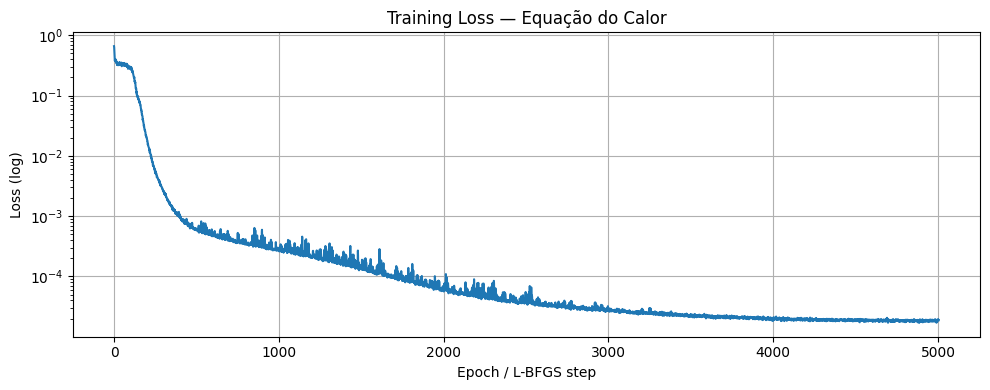

In [8]:
heat_model, heat_losses = run_pinn(
    residual_fn = compute_heat_residual,
    ic_fn = ic_sin_pi,
    bc_fn = bc_zero,
    analytical_fn = analytical_heat,
    param = 0.05,
    n_epochs = 5000,
    title = "Equação do Calor",
)

=== Burgers ===
Epoch [500/5000]  loss=0.143671  pde=0.057760  ic=0.006095  bc=0.002496  rh=0.000000
Epoch [1000/5000]  loss=0.047833  pde=0.023175  ic=0.001565  bc=0.000901  rh=0.000000
Epoch [1500/5000]  loss=0.021555  pde=0.004856  ic=0.000888  bc=0.000782  rh=0.000000
Epoch [2000/5000]  loss=0.010713  pde=0.002285  ic=0.000338  bc=0.000504  rh=0.000000
Epoch [2500/5000]  loss=0.005973  pde=0.001715  ic=0.000197  bc=0.000229  rh=0.000000
Epoch [3000/5000]  loss=0.006750  pde=0.002026  ic=0.000134  bc=0.000338  rh=0.000000
Epoch [3500/5000]  loss=0.001749  pde=0.001095  ic=0.000055  bc=0.000010  rh=0.000000
Epoch [4000/5000]  loss=0.001324  pde=0.000826  ic=0.000041  bc=0.000009  rh=0.000000
Epoch [4500/5000]  loss=0.001185  pde=0.000773  ic=0.000031  bc=0.000010  rh=0.000000
Epoch [5000/5000]  loss=0.001086  pde=0.000711  ic=0.000032  bc=0.000006  rh=0.000000

── Refinamento L-BFGS (200 steps) ──
Loss final após L-BFGS: 0.000495



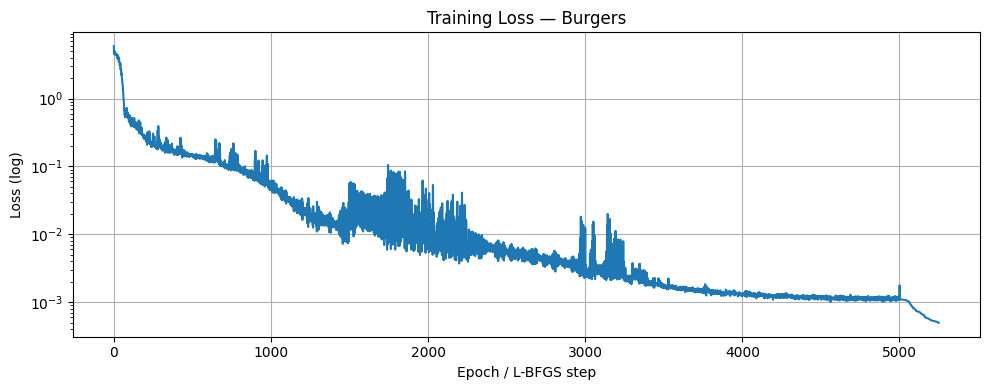

In [9]:
burgers_model, burgers_losses = run_pinn(
    residual_fn = compute_burgers_residual,
    ic_fn = ic_burgers,
    bc_fn = bc_zero,
    analytical_fn = analytical_burgers,
    param = 0.1,
    layers = [2, 64, 64, 64, 1],
    n_epochs = 5000,
    lr = 0.001,
    w_ic = 10.0,
    w_bc = 10.0,
    x_range = (-1.0, 1.0),
    y_range = (-1.15, 1.15),
    title = "Burgers",
)

=== Buckley-Leverett ===
Epoch [500/3000]  loss=0.480372  pde=0.220992  ic=0.001565  bc=0.006060  rh=0.010688
Epoch [1000/3000]  loss=0.432869  pde=0.077462  ic=0.001022  bc=0.011628  rh=0.010242
Epoch [1500/3000]  loss=0.404071  pde=0.046818  ic=0.000655  bc=0.011952  rh=0.010512
Epoch [2000/3000]  loss=0.256244  pde=0.044082  ic=0.000163  bc=0.004914  rh=0.011062
Epoch [2500/3000]  loss=0.269069  pde=0.052475  ic=0.000272  bc=0.005482  rh=0.010150
Epoch [3000/3000]  loss=0.344295  pde=0.048409  ic=0.000411  bc=0.008671  rh=0.011423

── Refinamento L-BFGS (200 steps) ──
Loss final após L-BFGS: 0.073557



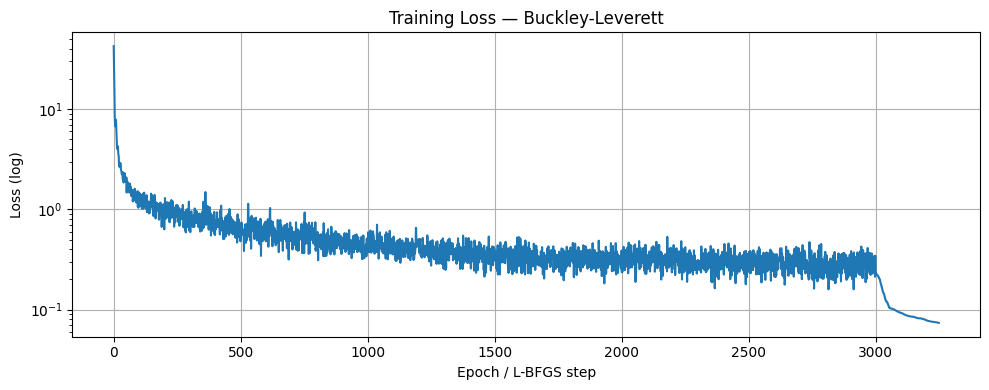

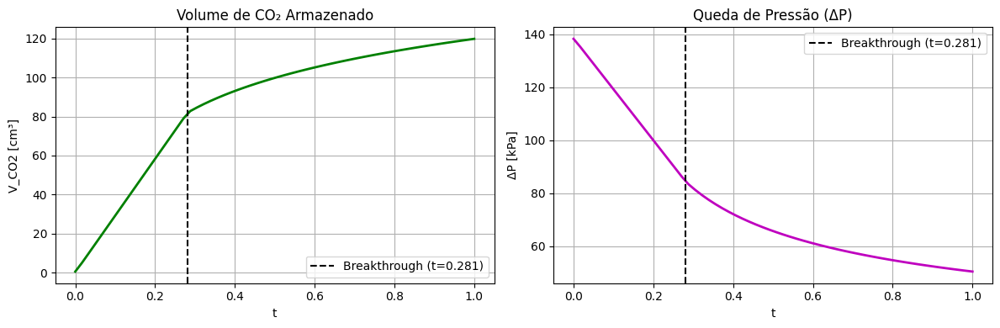

In [10]:
bl_model, bl_losses = run_pinn(
    residual_fn = compute_buckley_leverett_residual,
    ic_fn = ic_buckley_leverett,
    bc_fn = bc_buckley_leverett,
    analytical_fn = analytical_buckley_leverett,
    param = 5e-4,
    layers = [2, 64, 64, 64, 64, 1],
    n_epochs = 3000,
    w_ic = 20.0,
    w_bc = 20.0,
    w_rh = 10.0,
    x_range = (0.0, 1.0),
    y_range = (-0.05, 1.15),
    bc_left_only = True,
    use_adaptive_collocation = True,
    sigma_shock = sigma,
    upwind_fn = upwind_buckley_leverett,
    title = "Buckley-Leverett",
)

x_calc = np.linspace(0.0, 1.0, 200)
t_calc = np.linspace(0.0, 1.0, 60)
V_co2_list, dP_list = [], []

for tv in t_calc:
    S_prof = analytical_buckley_leverett(x_calc, tv)
    V_co2 = A_sec * L * phi * (1 - S_wc) * integrate.simpson(1 - S_prof, x=x_calc)
    lam_t = (c_krw * (S_prof**n_w) / mu_w) + (c_krg * ((1-S_prof)**n_g) / mu_g)
    dP    = (u_t * L / k) * integrate.simpson(1 / (lam_t + 1e-15), x=x_calc)
    V_co2_list.append(V_co2 * 1e6)
    dP_list.append(dP / 1e3)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(t_calc, V_co2_list, 'g-', lw=2)
ax1.axvline(1/sigma, color='k', ls='--', label=f'Breakthrough (t={1/sigma:.3f})')
ax1.set_xlabel('t'); ax1.set_ylabel('V_CO2 [cm³]')
ax1.set_title('Volume de CO₂ Armazenado'); ax1.legend(); ax1.grid(True)

ax2.plot(t_calc, dP_list, 'm-', lw=2)
ax2.axvline(1/sigma, color='k', ls='--', label=f'Breakthrough (t={1/sigma:.3f})')
ax2.set_xlabel('t'); ax2.set_ylabel('ΔP [kPa]')
ax2.set_title('Queda de Pressão (ΔP)'); ax2.legend(); ax2.grid(True)
plt.tight_layout(); plt.show()

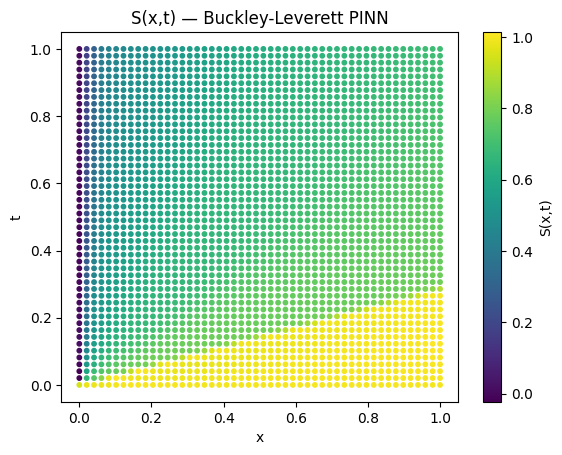

In [11]:
x_vals = np.linspace(0, 1, 50)
t_vals = np.linspace(0, 1, 50)
X_grid, T_grid = np.meshgrid(x_vals, t_vals)
X_flat = X_grid.flatten()[:, None]
T_flat = T_grid.flatten()[:, None]

x_tensor = torch.tensor(X_flat, dtype=torch.float32, device=device)
t_tensor = torch.tensor(T_flat, dtype=torch.float32, device=device)

bl_model.eval()
with torch.no_grad():
    u_pred = bl_model(x_tensor, t_tensor).cpu().numpy()

X_sr = np.hstack([X_flat, T_flat])
y_sr = u_pred.flatten()

scatter = plt.scatter(X_sr[:, 0], X_sr[:, 1], c=y_sr, cmap='viridis', s=10)
plt.colorbar(scatter, label='S(x,t)')
plt.xlabel('x'); plt.ylabel('t')
plt.title('S(x,t) — Buckley-Leverett PINN'); plt.show()

In [12]:
x_col = X_sr[:, 0]
t_col = X_sr[:, 1]

shock_pos = sigma * t_col
d_shock = x_col - shock_pos

steep = 30.0
behind_shock = 1.0 / (1.0 + np.exp(-steep * (shock_pos - x_col)))

X_sr_aug = np.hstack([
    X_sr,
    d_shock[:, None],
    behind_shock[:, None],
])

model_sr = PySRRegressor(
    niterations=500,
    populations=30,
    binary_operators=["+", "*", "-", "/"],
    unary_operators=[
        "exp", "tanh", "sqrt", "inv(x) = one(x) / x",
        "heaviside(x) = x > zero(x) ? one(x) : zero(x)",
        "relu(x) = max(zero(x), x)"
    ],
    extra_sympy_mappings={
        "inv": lambda x: 1.0 / x,
        "heaviside": lambda x: sp.Heaviside(x),
        "relu": lambda x: sp.Max(0, x),
    },

    nested_constraints={
        "heaviside": {"heaviside": 0, "relu": 0, "tanh": 0},
        "relu": {"relu": 0, "heaviside": 0},
        "sqrt": {"sqrt": 1},
    },
    variable_names=["x", "t", "d_shock", "behind_shock"],
    maxsize=25,
    parsimony=0.001,
    verbosity=1,
)

model_sr.fit(X_sr_aug, y_sr)

c:\Users\frena\AntigravityProjects\PINN_porous_media\.venv\Lib\site-packages\pysr\sr.py:1359: FutureWarning: `variable_names` is a data-dependent parameter and should be passed when fit is called. Ignoring parameter; please pass `variable_names` during the call to fit instead.
  warnings.warn(
Compiling Julia backend...


PySRRegressor.equations_ = [
	    pick     score                                           equation  \
	0         0.000000                                          0.6874347   
	1         0.053752                                           sqrt(x0)   
	2         0.147614                                     sqrt(tanh(x0))   
	3         0.524659                               tanh(sqrt(sqrt(x0)))   
	4         0.115757                                 tanh(exp(x0 - x1))   
	5         1.485947                          tanh(sqrt(sqrt(x0)) / x3)   
	6         0.038962                    tanh(sqrt(sqrt(tanh(x0))) / x3)   
	7         0.314738                   sqrt(tanh(sqrt(x0) / (x1 + x3)))   
	8         0.400094             sqrt(tanh(sqrt(x0) / (x1 + tanh(x3))))   
	9         0.623569       tanh(sqrt(sqrt(x0) / (x1 + 0.4781262)) / x3)   
	10        0.147706  tanh(sqrt(sqrt(x0) / (x1 + 0.42514896)) + (0.9...   
	11        0.338014  tanh(sqrt((sqrt(x0) + exp(x2 / 0.015962498)) /...   
	12      

In [13]:
eq_sympy = model_sr.sympy()
x0, x1, x2, x3 = sp.symbols('x0 x1 x2 x3')
x, t, d_shock, behind_shock = sp.symbols('x t d_shock behind_shock')

display(eq_sympy.subs({x0: x, x1: t, x2: d_shock, x3: behind_shock}))

y_sym_pred = model_sr.predict(X_sr_aug)
print(f"\nMSE Simbólica vs PINN: {np.mean((y_sym_pred - y_sr)**2):.6e}")

sqrt(tanh(Max(0, sqrt(x/(2*t + x + 0.01184301) + exp(84.4379933817501*d_shock)) - 0.050706107)))


MSE Simbólica vs PINN: 1.916781e-04


In [14]:
x_lo, x_hi = 0.0, 1.0
n_x, n_frames = 150, 60
x_plot   = np.linspace(x_lo, x_hi, n_x)
t_frames = np.linspace(0, 1, n_frames)

steep = 50.0

def make_X_aug(x_arr, t_val):
    x_col     = x_arr
    t_col     = np.full(len(x_arr), t_val)
    shock_pos = sigma * t_col
    d_shock   = (x_col - shock_pos)[:, None]
    soft_step = (1 / (1 + np.exp(-steep * (shock_pos - x_col))))[:, None]
    return np.hstack([x_col[:, None], t_col[:, None], d_shock, soft_step])

pinn_frames, analytic_frames, sym_frames = [], [], []
bl_model.eval()
x_t = torch.tensor(x_plot[:, None], dtype=torch.float32, device=device)

for t_val in t_frames:
    t_t = torch.full((n_x, 1), float(t_val), dtype=torch.float32, device=device)
    with torch.no_grad():
        pinn_frames.append(bl_model(x_t, t_t).cpu().numpy().flatten())
    analytic_frames.append(analytical_buckley_leverett(x_plot, t_val))
    sym_frames.append(model_sr.predict(make_X_aug(x_plot, t_val)))

fig, ax = plt.subplots(figsize=(9, 5))
line_anal, = ax.plot([], [], 'b-',  lw=2,   label='Analítico (Welge)')
line_pinn, = ax.plot([], [], 'r--', lw=1.8, label='PINN')
line_sym,  = ax.plot([], [], 'g-.', lw=1.8, label='Regressão Simbólica')
time_text  = ax.text(0.02, 0.93, '', transform=ax.transAxes, fontsize=12)
ax.set_xlim(x_lo, x_hi); ax.set_ylim(-0.1, 1.2)
ax.set_xlabel('x'); ax.set_ylabel('S(x,t)')
ax.set_title('Buckley-Leverett: Analítico vs PINN vs Regressão Simbólica')
ax.legend(); ax.grid(True)

def update(frame):
    line_anal.set_data(x_plot, analytic_frames[frame])
    line_pinn.set_data(x_plot, pinn_frames[frame])
    line_sym.set_data(x_plot, sym_frames[frame])
    time_text.set_text(f't = {t_frames[frame]:.3f}')
    return line_anal, line_pinn, line_sym, time_text

ani = animation.FuncAnimation(fig, update, frames=n_frames, interval=80, blit=True)
import os
os.makedirs("outputs", exist_ok=True)
ani.save("outputs/buckley_leverett_simbolica.gif", writer="pillow", fps=12)
print("GIF salvo em: outputs/buckley_leverett_simbolica.gif")
plt.close()
display(HTML(ani.to_jshtml()))